# 06 — Foco: 4 relações com views

| # | Relação | Pergunta de negócio |
|---|---|---|
| 1 | `content_category` × views | Algum tema alcança mais gente? |
| 2 | `content_description` × views | O texto da legenda (tamanho, tom, palavras) muda o alcance? |
| 3 | `follower_count` × views | Creators maiores entregam mais views? |
| 4 | `is_sponsored` × views | Post patrocinado alcança mais? |

Para cada relação: descrição → teste → **tamanho do efeito com IC95** → **efeito mínimo detectável (MDE)** → gráfico.
O MDE responde: *se existisse um efeito relevante, estes dados o teriam encontrado?* (poder de 80%, α = 5%).

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import focus
MEAN_VIEWS = df.views.mean()

52,214 posts


## 1. `content_category` × views

In [2]:
cat = focus.category_vs_views(df)
display(Markdown(f"**Resposta:** {cat.verdict}"))
display(cat.evidence.round(1))
display(cat.details["Comparações par a par"].round(4))

**Resposta:** Categoria não muda as views: diferença máxima de 1.6 views (0.015%) entre categorias (Kruskal p=0.27, ε²=0.00005). Os dados detectariam diferenças a partir de ~3 views (0.03%), então um efeito de negócio relevante (ex.: 5%) teria aparecido.

,posts,média,IC95 inf,IC95 sup,mediana,p10,p90
categoria,,,,,,,
beauty,21023,10099.9000,10098.6000,10101.3000,10100.0000,9973.0000,10228.0000
lifestyle,20761,10100.0000,10098.7000,10101.4000,10100.0000,9973.0000,10227.0000
tech,10430,10101.5000,10099.6000,10103.4000,10102.0000,9972.0000,10230.0000


,par,diferença (views),diferença (%),p_value,MDE (views),q_value
0,beauty vs lifestyle,-0.0601,-0.0006,0.9510,2.7419,0.9510
1,beauty vs tech,-1.5603,-0.0154,0.1932,3.3563,0.3164
2,lifestyle vs tech,-1.5002,-0.0149,0.2110,3.3633,0.3164


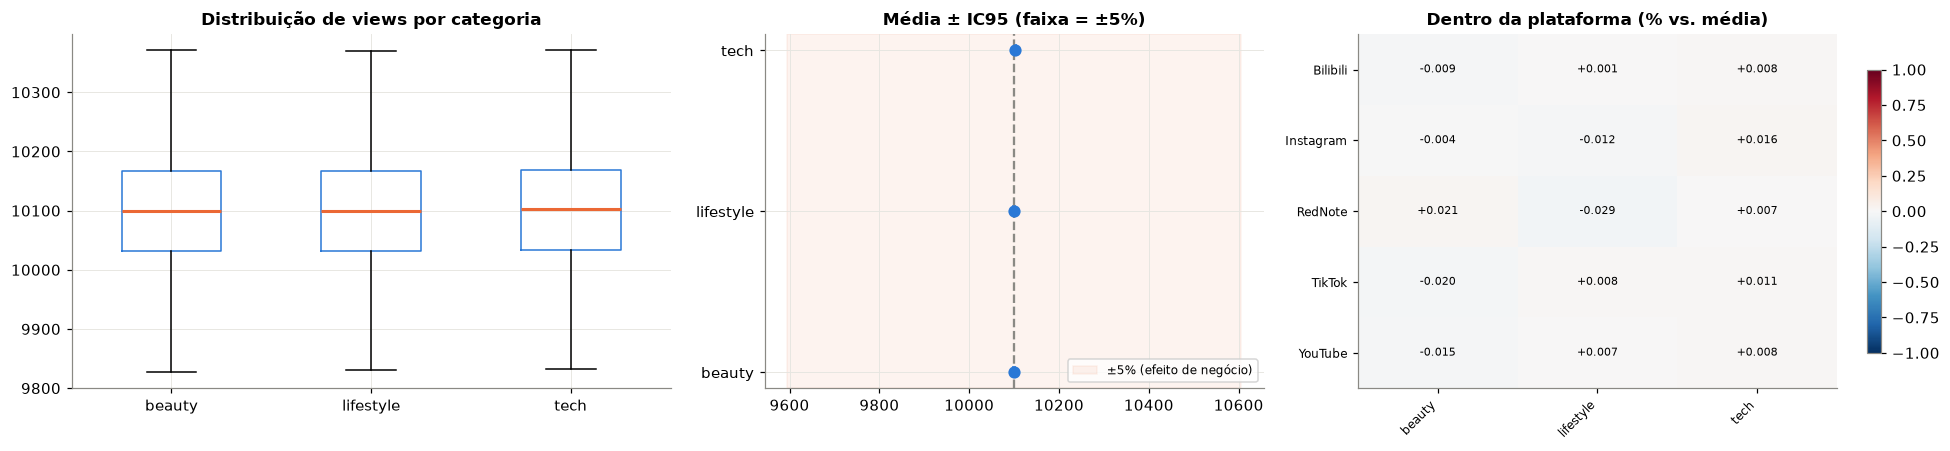

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1.2, 1, 1.2]})
cats = cat.evidence.index.tolist()
axes[0].boxplot([df.loc[df.content_category == c, "views"] for c in cats], tick_labels=cats, widths=0.5, showfliers=False,
                medianprops={"color": plots.ORANGE, "linewidth": 2}, boxprops={"color": plots.BLUE})
axes[0].set_title("Distribuição de views por categoria")
ev = cat.evidence
axes[1].errorbar(ev["média"], range(len(ev)), xerr=[ev["média"] - ev["IC95 inf"], ev["IC95 sup"] - ev["média"]],
                 fmt="o", color=plots.BLUE, capsize=4, markersize=7)
axes[1].axvspan(MEAN_VIEWS * 0.95, MEAN_VIEWS * 1.05, color=plots.ORANGE, alpha=0.08, label="±5% (efeito de negócio)")
axes[1].axvline(MEAN_VIEWS, color=plots.GRAY, linestyle="--")
axes[1].set_yticks(range(len(ev)), ev.index); axes[1].set_title("Média ± IC95 (faixa = ±5%)")
axes[1].legend(fontsize=8, loc="lower right")
plots.heatmap(axes[2], cat.details["Dentro de cada plataforma (% vs. média da plataforma)"], "Dentro da plataforma (% vs. média)",
              vmin=-1, vmax=1, fmt="{:+.3f}")
fig.tight_layout(); plt.show()

**Leitura:** as 3 categorias têm a mesma distribuição. As médias diferem em ≤ 1,6 views (0,015%), com ICs sobrepostos. No painel do meio, a faixa laranja de ±5% engole tudo.
O MDE é de ~3 views: o teste enxergaria até 0,03% de diferença, então a ausência de efeito é **comprovada**, não falta de poder. O padrão se repete dentro de cada plataforma (±0,03%).

## 2. `content_description` × views (NLP)

In [4]:
desc = focus.description_vs_views(df)
display(Markdown(f"**Resposta:** {desc.verdict}"))
display(desc.evidence.round(4))
display(desc.details["Modelo de texto (TF-IDF + Ridge)"].round(4))
display(df[["content_description", "content_category", "views"]].sample(5, random_state=1))

**Resposta:** A legenda não muda as views. Tamanho e sentimento têm |ρ| ≤ 0.002 (detectável a partir de 0.012). 0 palavras distinguem posts de muitas e poucas views (|z| > 1,96), e um modelo de texto (TF-IDF + Ridge, 5,000 termos) tem R² = -0.0009. Os textos são frases aleatórias, sem relação com o tema do post.

,ρ Spearman,p_value,MDE ρ
característica,,,
palavras,-0.0012,0.7911,0.0123
caracteres,-0.0016,0.7214,0.0123
sentimento,0.0015,0.7310,0.0123


,vocabulário,alpha,R² médio,R² desvio
0,5000,100.0000,-0.0009,0.0009


,content_description,content_category,views
47207,Personal address produce affect young right th...,tech,10070
27004,Summer I really environment debate stock full ...,beauty,10034
44014,Leg eye behavior success become leave position...,tech,9934
8758,Budget half draw official small only garden de...,lifestyle,10000
42981,Yard together suddenly pick instead number beh...,tech,10191


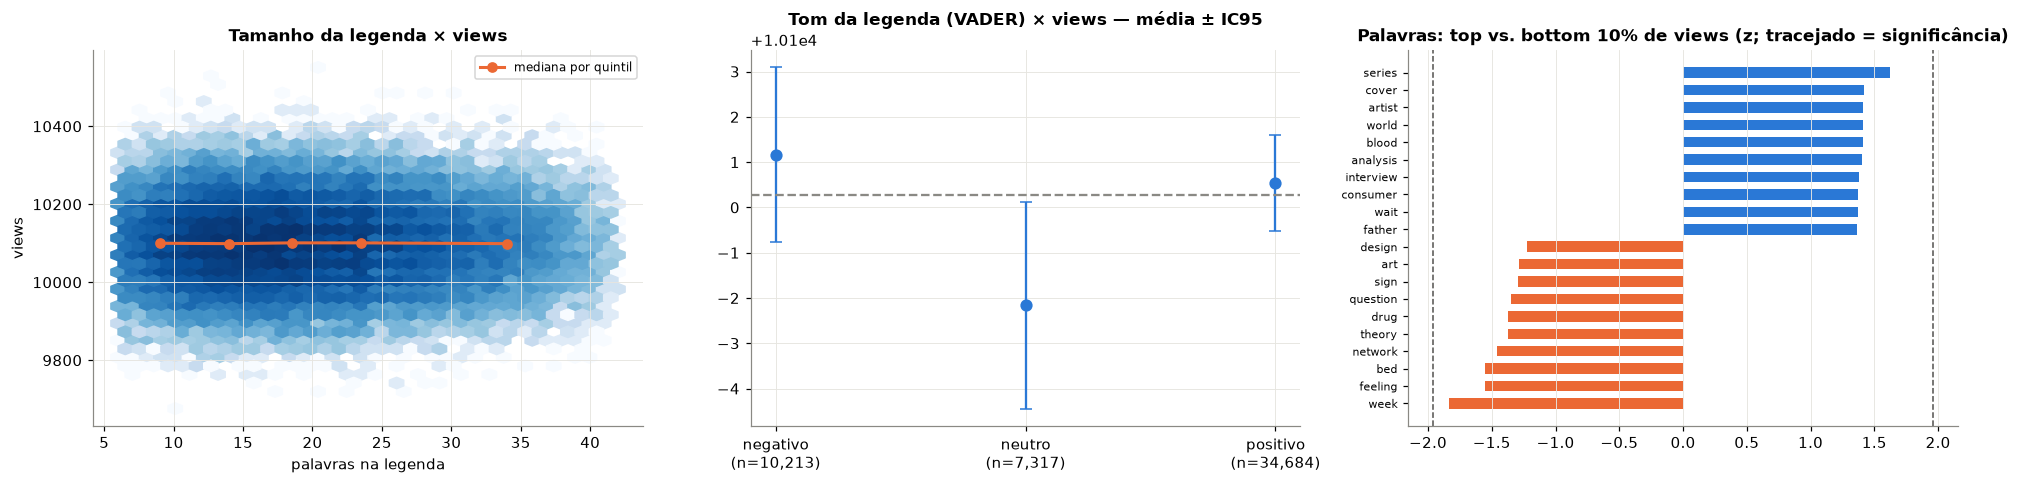

In [5]:
feats = focus.description_features(df)
kw = desc.details["Palavras mais típicas: top 10% vs. bottom 10% de views"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hexbin(feats["palavras"], df["views"], gridsize=35, cmap="Blues", bins="log")
q = desc.details["Views por quintil de tamanho da legenda (palavras)"]
mids = [float(i.split(",")[0][1:]) / 2 + float(i.split(",")[1][:-1]) / 2 for i in q.index]
axes[0].plot(mids, q["median"], "o-", color=plots.ORANGE, linewidth=2, label="mediana por quintil")
axes[0].set_xlabel("palavras na legenda"); axes[0].set_ylabel("views"); axes[0].set_title("Tamanho da legenda × views"); axes[0].legend(fontsize=8)
sent_bins = pd.cut(feats["sentimento"], [-1.01, -0.05, 0.05, 1.01], labels=["negativo", "neutro", "positivo"])
g = df.groupby(sent_bins, observed=True)["views"].agg(["mean", "sem", "size"])
axes[1].errorbar(range(len(g)), g["mean"], yerr=1.96 * g["sem"], fmt="o", color=plots.BLUE, capsize=4, markersize=7)
axes[1].set_xticks(range(len(g)), [f"{i}\n(n={n:,})" for i, n in zip(g.index, g["size"])])
axes[1].axhline(MEAN_VIEWS, color=plots.GRAY, linestyle="--"); axes[1].set_title("Tom da legenda (VADER) × views — média ± IC95")
kw_plot = kw.iloc[::-1]
axes[2].barh(kw_plot["word"], kw_plot["z"], color=[plots.BLUE if z > 0 else plots.ORANGE for z in kw_plot["z"]], height=0.6)
for v in (-1.96, 1.96):
    axes[2].axvline(v, color=plots.INK, linestyle="--", linewidth=1)
axes[2].set_title("Palavras: top vs. bottom 10% de views (z; tracejado = significância)"); axes[2].tick_params(axis="y", labelsize=7)
axes[2].grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

**Leitura:** tamanho e tom da legenda não mudam as views (|ρ| ≤ 0,002 contra um MDE de 0,012), e nenhuma palavra cruza a linha de significância.
O modelo de texto (5 mil termos, uni e bigramas) tem R² ≈ 0. As legendas são frases aleatórias (ex.: *"Professional radio usually something letter half pattern…"*) sem relação com a categoria do post. Por isso **não há semântica a extrair**.
Não há "?" nem "!" em nenhuma legenda, então essas características não puderam ser testadas.

## 3. `follower_count` × views

In [6]:
fol = focus.followers_vs_views(df)
display(Markdown(f"**Resposta:** {fol.verdict}"))
display(fol.evidence.round(5))
display(fol.details["Views por decil de seguidores"].round(1))

**Resposta:** Seguidores não trazem views: ρ = 0.0046 (detectável a partir de 0.012). Cada +100 mil seguidores somam +0.17 views (IC95 -0.13 a +0.47), e a elasticidade é 0.0001, ou seja, dobrar a base muda as views em +0.004%. Um creator de 5 mil e um de 1 milhão têm a mesma mediana de views. Nas redes reais, a elasticidade costuma ficar entre 0,5 e 1, então isso é atípico.

,valor,IC95 inf,IC95 sup,p_value
ρ Spearman,0.0046,NaN,NaN,0.2903
r Pearson,0.0050,NaN,NaN,0.2558
views a mais por +100 mil seguidores,0.1727,-0.1252,0.4706,0.2558
elasticidade (log-log),0.0001,-0.0000,0.0001,0.1972
MDE ρ (80% de poder),0.0123,NaN,NaN,NaN


,size,mean,median
"1,013–101,069",5222,10098.8000,10098.0000
"101,069–201,634",5221,10101.1000,10100.0000
"201,634–299,354",5221,10099.4000,10101.0000
"299,354–398,541",5222,10099.3000,10098.0000
"398,541–498,490",5221,10098.8000,10100.0000
"498,490–599,598",5221,10101.7000,10104.0000
"599,598–700,456",5222,10102.1000,10101.0000
"700,456–799,657",5221,10100.1000,10099.0000
"799,657–898,837",5221,10101.6000,10102.0000
"898,837–999,998",5222,10099.8000,10099.0000


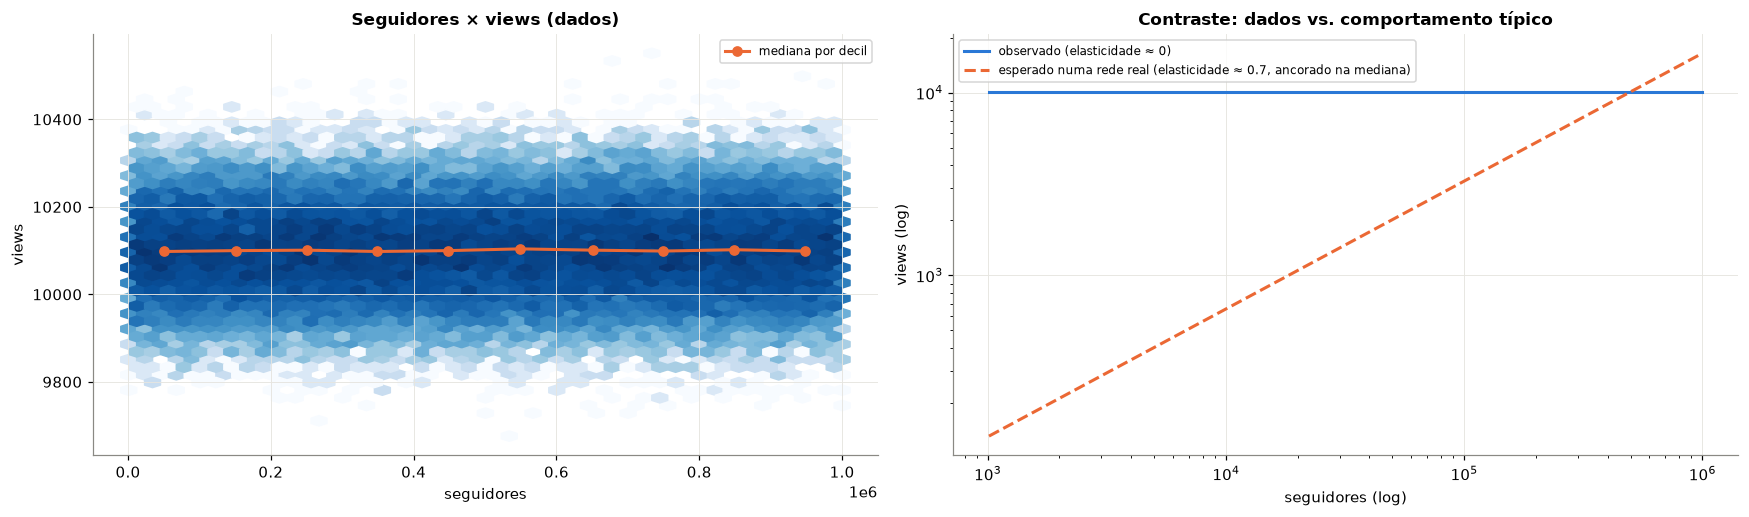

In [7]:
REAL_ELASTICITY = 0.7  # typical order of magnitude in real platforms (illustrative contrast)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].hexbin(df["follower_count"], df["views"], gridsize=45, cmap="Blues", bins="log")
dec = df.groupby(pd.qcut(df.follower_count, 10), observed=True).agg(x=("follower_count", "median"), y=("views", "median"))
axes[0].plot(dec["x"], dec["y"], "o-", color=plots.ORANGE, linewidth=2, label="mediana por decil")
axes[0].set_xlabel("seguidores"); axes[0].set_ylabel("views"); axes[0].set_title("Seguidores × views (dados)"); axes[0].legend(fontsize=8)
x = np.linspace(df.follower_count.min(), df.follower_count.max(), 200)
anchor_x, anchor_y = df.follower_count.median(), df.views.median()
axes[1].plot(x, np.full_like(x, anchor_y), color=plots.BLUE, linewidth=2, label="observado (elasticidade ≈ 0)")
axes[1].plot(x, anchor_y * (x / anchor_x) ** REAL_ELASTICITY, color=plots.ORANGE, linewidth=2, linestyle="--",
             label=f"esperado numa rede real (elasticidade ≈ {REAL_ELASTICITY}, ancorado na mediana)")
axes[1].set_yscale("log"); axes[1].set_xscale("log"); axes[1].set_xlabel("seguidores (log)"); axes[1].set_ylabel("views (log)")
axes[1].set_title("Contraste: dados vs. comportamento típico"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Leitura:** a nuvem é uma faixa horizontal: creators de 1 mil e de 1 milhão têm a mesma mediana (~10.100 views). A elasticidade é 0,0001.
Numa rede real (laranja), 100x mais seguidores renderiam ~25x mais views. Aqui, renderiam **0x**.
**Implicação prática:** "views por seguidor" vai de 10 (nano) a 0,01 (mega). Pagar por seguidores é pagar por algo que não vira alcance.

## 4. `is_sponsored` × views

In [8]:
spo = focus.sponsorship_vs_views(df)
display(Markdown(f"**Resposta:** {spo.verdict}"))
display(spo.evidence.round(3))

**Resposta:** Patrocínio não traz views: +0.3 views (+0.003%, IC95 -1.4 a +2.0); estratificado: +0.4 views. Os dados detectariam diferenças a partir de ~2.5 views (0.025%). 0 de 21 condições (porte, plataforma, categoria, patrocinador, disclosure) com efeito.

,diferença (views),IC95 inf,IC95 sup,diferença (%),p_value,MDE (views)
bruta,0.2880,-1.4500,2.0260,0.0030,0.7450,2.4790
estratificada (plataforma × formato × categoria × porte),0.4210,-1.3100,2.1520,0.0040,0.6330,2.4790


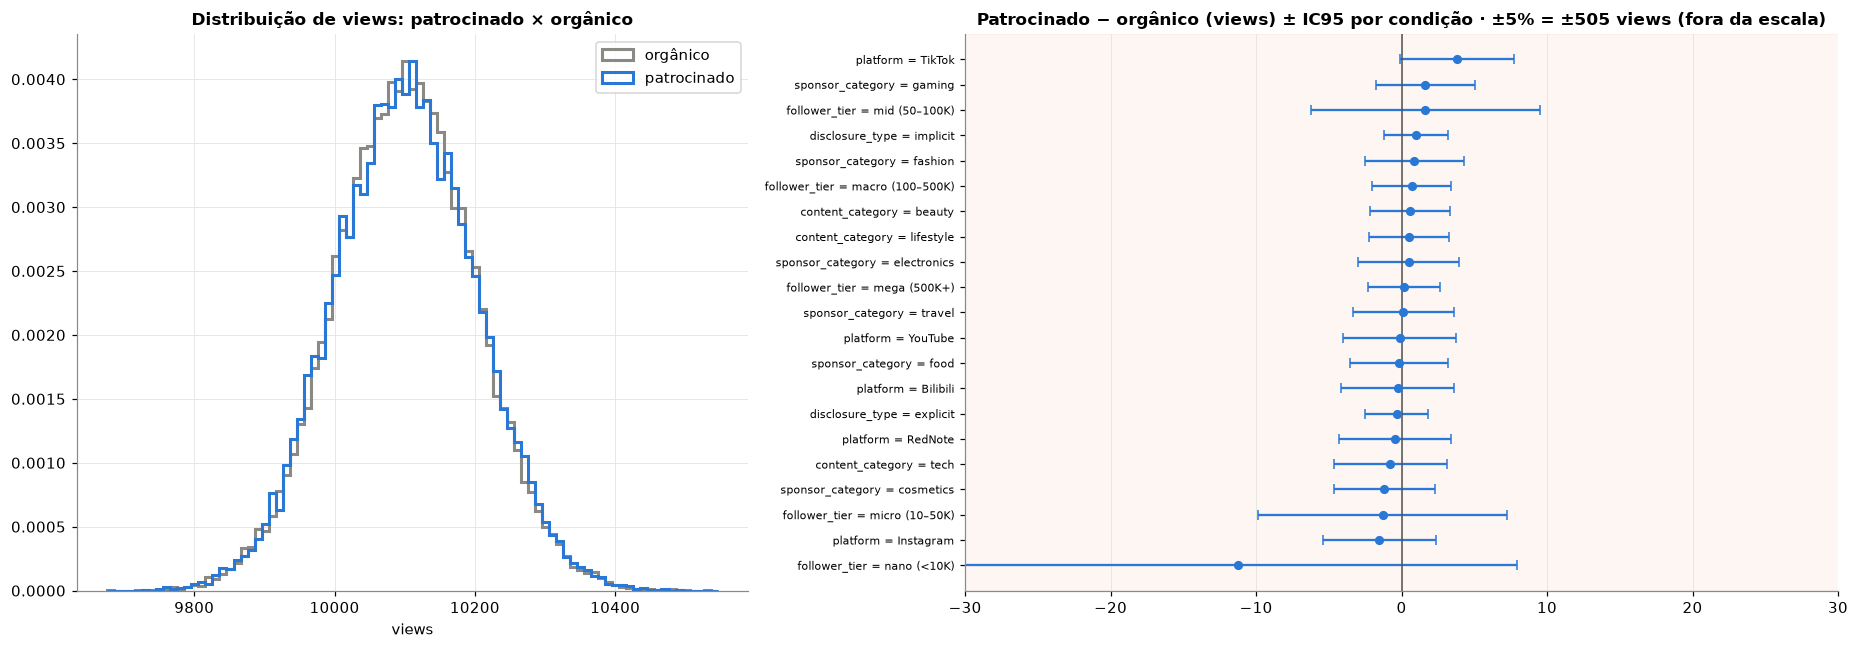

In [9]:
conds = spo.details["Por condição"].sort_values("diferença (views)")
mde = spo.evidence.loc["bruta", "MDE (views)"]
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.3]})
bins = np.arange(df.views.min(), df.views.max(), 10)
for flag, color, label in [(False, plots.GRAY, "orgânico"), (True, plots.BLUE, "patrocinado")]:
    axes[0].hist(df.loc[df.is_sponsored == flag, "views"], bins=bins, density=True, histtype="step", linewidth=2, color=color, label=label)
axes[0].set_title("Distribuição de views: patrocinado × orgânico"); axes[0].legend(); axes[0].set_xlabel("views")
y = np.arange(len(conds))
axes[1].errorbar(conds["diferença (views)"], y, xerr=[conds["diferença (views)"] - conds["IC95 inf"], conds["IC95 sup"] - conds["diferença (views)"]],
                 fmt="o", color=plots.BLUE, capsize=3, markersize=5)
axes[1].axvline(0, color=plots.INK, linewidth=1)
axes[1].axvspan(-MEAN_VIEWS * 0.05, MEAN_VIEWS * 0.05, color=plots.ORANGE, alpha=0.06)
axes[1].set_xlim(-30, 30)
axes[1].set_yticks(y, conds["condição"], fontsize=7)
axes[1].set_title("Patrocinado − orgânico (views) ± IC95 por condição · ±5% = ±505 views (fora da escala)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

**Leitura:** as duas distribuições se sobrepõem. A diferença é de +0,3 views (IC95 −1,4 a +2,0), e a estratificada (mesma plataforma, formato, categoria e porte) é de +0,4.
Nenhuma das 21 condições se afasta de zero após a correção. O maior ponto (TikTok, +3,8 views, q = 0,95) é ruído, e um efeito de 5% (±505 views) ficaria **fora do gráfico**.

## 5. Síntese: o que os dados permitem afirmar

In [10]:
summary = pd.DataFrame([
    {"relação": "content_category × views", "efeito observado": f"{cat.evidence['média'].max() - cat.evidence['média'].min():.1f} views (máx. entre categorias)",
     "detectável a partir de": f"{cat.details['Comparações par a par']['MDE (views)'].max():.1f} views", "conclusão": "sem efeito (comprovado)"},
    {"relação": "content_description × views", "efeito observado": f"|ρ| ≤ {desc.evidence['ρ Spearman'].abs().max():.3f}; R² texto = {desc.details['Modelo de texto (TF-IDF + Ridge)']['R² médio'].iloc[0]:.4f}",
     "detectável a partir de": f"ρ = {focus.mde_correlation(len(df)):.3f}", "conclusão": "sem efeito; texto sem semântica"},
    {"relação": "follower_count × views", "efeito observado": f"ρ = {fol.evidence.loc['ρ Spearman', 'valor']:.4f}; elasticidade {fol.evidence.loc['elasticidade (log-log)', 'valor']:.4f}",
     "detectável a partir de": f"ρ = {focus.mde_correlation(len(df)):.3f}", "conclusão": "sem efeito (atípico vs. redes reais)"},
    {"relação": "is_sponsored × views", "efeito observado": f"{spo.evidence.loc['bruta', 'diferença (views)']:+.1f} views",
     "detectável a partir de": f"{spo.evidence.loc['bruta', 'MDE (views)']:.1f} views", "conclusão": "sem efeito (comprovado)"},
]).set_index("relação")
summary

,efeito observado,detectável a partir de,conclusão
relação,,,
content_category × views,1.6 views (máx. entre categorias),3.4 views,sem efeito (comprovado)
content_description × views,|ρ| ≤ 0.002; R² texto = -0.0009,ρ = 0.012,sem efeito; texto sem semântica
follower_count × views,ρ = 0.0046; elasticidade 0.0001,ρ = 0.012,sem efeito (atípico vs. redes reais)
is_sponsored × views,+0.3 views,2.5 views,sem efeito (comprovado)


**Conclusão:** nas 4 relações, o teste tinha poder para enxergar efeitos **~150 a 200 vezes menores** que um efeito de negócio relevante (5% = ~505 views; o efeito mínimo detectável é de 2,5–3,4 views) e não encontrou nada.
A impressão de que "os dados não trazem insight" está correta e agora está **quantificada**. O insight de negócio é justamente este:
**tema, legenda, tamanho do creator e patrocínio não compram alcance neste dataset**, então a decisão deve ser por custo (ver `strategy-recommendations.md`).

> Por que o MDE é tão pequeno? Porque as views quase não variam (desvio de 100 em 10.100, 1%). Em dados reais, a variação costuma ser de 100% ou mais, e o MDE seria proporcionalmente maior. O método já calcula isso automaticamente.